# Natural Language Processing Demystified | Classification with Naive Bayes
https://nlpdemystified.org<br>
https://github.com/futuremojo/nlp-demystified
<br><br>
Course module for this demo: https://www.nlpdemystified.org/course/naive-bayes

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy

from sklearn import metrics
from sklearn import model_selection
from sklearn.datasets import fetch_20newsgroups
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# First pass at building a Naive Bayes model.


As with our TF-IDF demo, we'll use the topic modelling file we have performed in the previous class.

In [8]:
import pandas as pd
training_corpus = pd.read_excel('topics.xlsx').dropna()

In [9]:
print('Training data size: {}'.format(len(training_corpus)))

Training data size: 14103


The training data we downloaded not only includes the posts but also a label ("target") for each post representing its topic. In our case, it will be the column 'labels' of our dataset.

In [10]:
# These are the labels/targets for each post.
print(training_corpus['labels'])

0        5
1        5
2        7
3        1
4        3
        ..
14215    8
14216    9
14217    3
14218    7
14219    7
Name: labels, Length: 14103, dtype: int64


In [11]:
# The first post along with its corresponding label.
print(training_corpus['abstract'][0])

first_doc_label = training_corpus['labels'][0]
print('Corresponding topic: {}'.format(training_corpus['labels'][first_doc_label]))

mn doped bfo thin films glass substrates simple spin coating method structural optical properties examined . results obtained x - ray diffraction pattern mn doped bfo confirmed rhombohedral distorted stress relaxation . bi - o fe - o bonds detected , shifting stretching bending vibrations pristine bfo observed ftir analysis . xps spectra mn - doped bfo thin film declared valence states bi , fe mn respective binding energies . narrow optical band gap energy 1.65 ev observed mn doped bfo pristine bfo ( 2.17 ev ) indicated reduction band gap energy o 2p valence fe 3d conduction band mn doping .
Corresponding topic: 7


When starting off with a dataset, it's a good idea to check its distribution. In this case, we can see at a glance this dataset is relatively balanced.

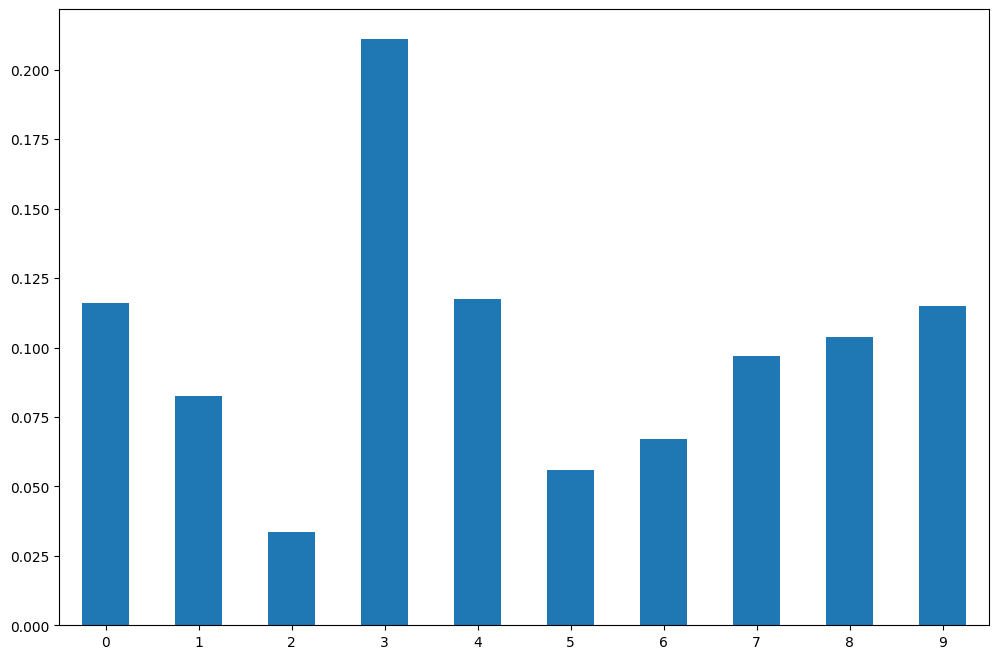

In [12]:
bins, counts = np.unique(training_corpus['labels'], return_counts=True)
freq_series = pd.Series(counts/len(training_corpus['abstract']))
plt.figure(figsize=(12, 8))
ax = freq_series.plot(kind='bar')
ax.set_xticklabels(bins, rotation=0)
plt.show()

Now that we have our training set, we can split it further into train and validation sets. If you have a small training set like this one, you can use alternative techniques like cross-validation but we'll show a split here since we talked about it in the model building module. scikit-learn has a module to help us do this.<br>
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [13]:
# Shuffle, then split the data into train and validation sets. Set the random_state
# to 1 for reproducibility.
train_data, val_data, train_labels, val_labels = train_test_split(training_corpus['abstract'], training_corpus['labels'], train_size=0.8, random_state=1)
print('Training data size: {}'.format(len(train_data)))
print('Validation data size: {}'.format(len(val_data)))

Training data size: 11282
Validation data size: 2821


Now that we have our train-validation split, let's create our spaCy tokenizer. Up to this point, we've been using the **en_core_web_sm** model.

In [14]:
nlp = spacy.load('en_core_web_sm')

By default, it comes up with a preprocessing pipeline with several components enabled. We can view these components through the *pipe_names* attribute.

In [15]:
nlp.pipe_names

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']

In the previous demos, we individually disabled any component we didn't need. For our first pass at building a Naive Bayes classifier, we'll try tokenizing alone. Nothing else. Since that's the case, it's easier to instantiate a blank pipeline.<br>
https://spacy.io/api/top-level#spacy.blank

In [16]:
nlp = spacy.blank('en')

# There should be no pipeline components.
nlp.pipe_names

[]

In [17]:
# For this exercise, we'll remove punctuation and spaces (which
# includes newlines), filter for tokens consisting of alphabetic
# characters only, and return the token text.
nlp.Defaults.stop_words.add("nan")

def spacy_tokenizer(doc):
  return [t.text for t in nlp(doc) if \
          not t.is_punct and \
          not t.is_space]

We'll vectorize using the **TfidfVectorizer**.

In [18]:
%%time
vectorizer = TfidfVectorizer(tokenizer=spacy_tokenizer)
train_feature_vects = vectorizer.fit_transform(train_data)

c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\feature_extraction\text.py:528: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


CPU times: total: 3.27 s
Wall time: 9.48 s


Scikit-learn includes a multinomial naive bayes classifier.<br>
https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html

Calling *fit* on the classifier and passing it the feature vectors and corresponding labels kicks off the training.

In [19]:
# Instantiate a classifier with the default settings.
nb_classifier = MultinomialNB()
nb_classifier.fit(train_feature_vects, train_labels)
nb_classifier.get_params()

{'alpha': 1.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': 'warn'}

Now that we know about the **F1 score** and have a multiclass problem, let's look at the F1 score on the training data. Since the dataset is balanced, accuracy could work here as well but we'll look at F1 since we introduced it. scikit-learn has a module called **metrics** we can leverage. It contains a variety of scoring utilities we can use.<br>
https://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics<br>
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html#sklearn.metrics.f1_score<br>
https://scikit-learn.org/stable/modules/model_evaluation.html#precision-recall-f-measure-metrics<br>

In [20]:
# Get predictions on training set and calculate F1 score.
# See documentation above for more details on what "macro" means.
train_preds = nb_classifier.predict(train_feature_vects)
print('F1 score on initial training set: {}'.format(metrics.f1_score(train_labels, train_preds, average='macro')))

F1 score on initial training set: 0.5926631642158522


So right off the bat, using simple preprocessing and vectorization, and the default settings on the Naive Bayes classifier, we get a model with a decent F1 score.<br><br>

Let's plot a confusion matrix to see what's going on:<br>
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html<br>
https://scikit-learn.org/stable/modules/model_evaluation.html#confusion-matrix

In [21]:
# Vectorize the validation data.
val_feature_vects = vectorizer.transform(val_data)

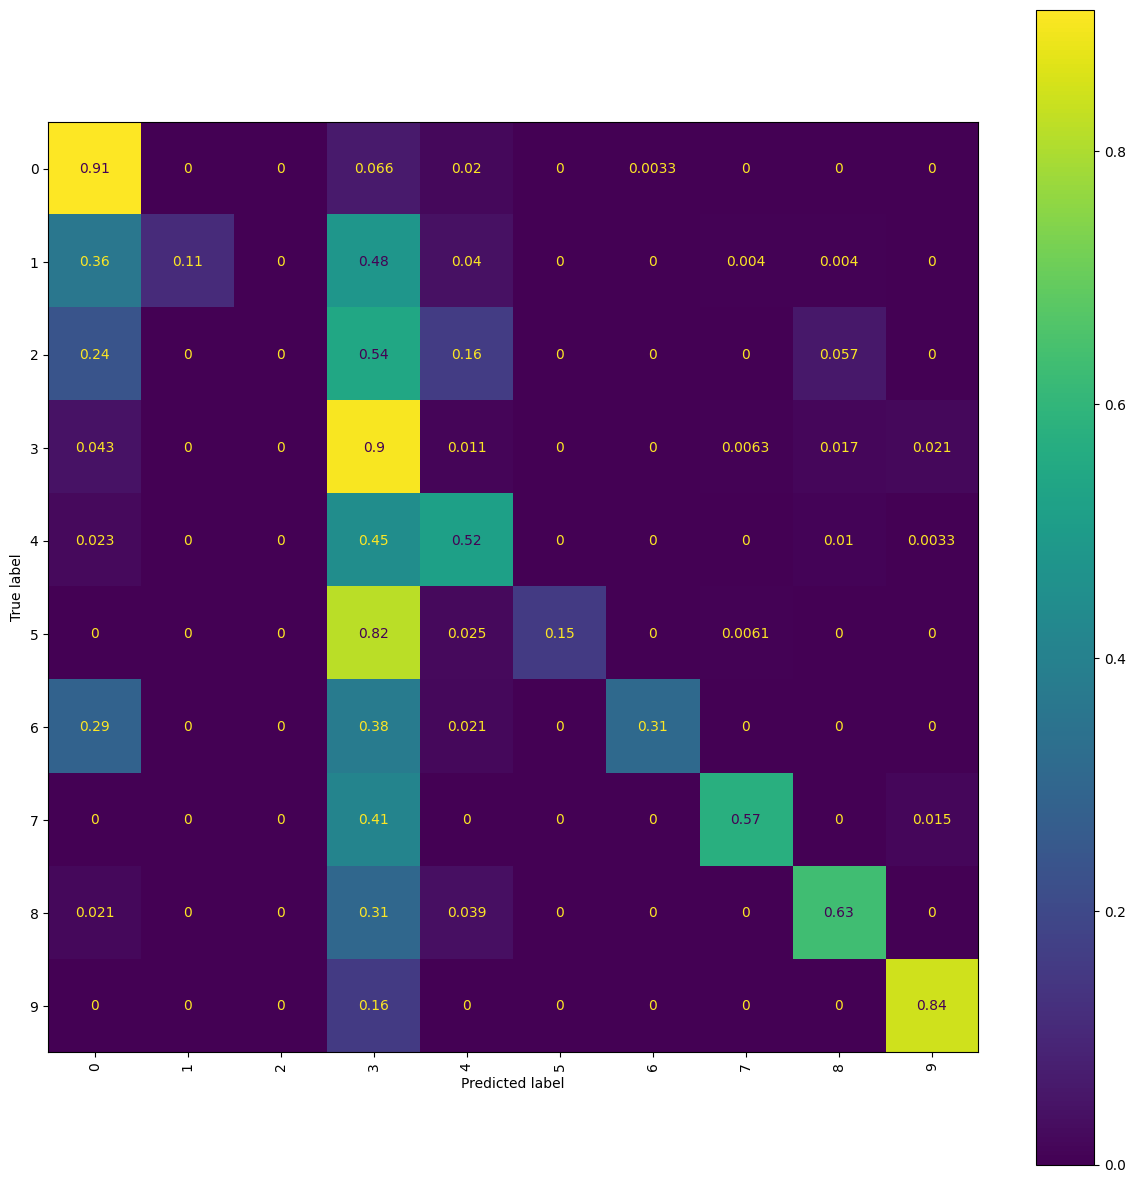

In [22]:
# Set the size of the plot.
fig, ax = plt.subplots(figsize=(15, 15))

# Create the confusion matrix.
disp = ConfusionMatrixDisplay.from_estimator(nb_classifier, val_feature_vects, val_labels, normalize='true', xticks_rotation='vertical', ax=ax)
# If you had an error, upgrade your scikit-learn package.
# pip uninstall scikit-learn
# pip install scikit-learn==1.0.2

Similar to what we saw in the slides, the y-axis represents the true labels and the x-axis represents the predictions. Each square's brightness represents the number of posts assigned to that class. What we ideally want is brightness along the diagonal (top-left to bottom-right) which represent correct predictions, and little to no brightness anywhere else.
<br><br>

Let's take a look at **precision** and **recall** for each label:<br>
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html<br>
https://scikit-learn.org/stable/modules/model_evaluation.html#classification-report

The next celll is just to be aligned with the original tutorial and avoid a lot of rewrites.

In [23]:
# Predict and evaluate.
val_preds = nb_classifier.predict(val_feature_vects)
print('F1 score on filtered validation set: {}'.format(metrics.f1_score(val_labels, val_preds, average='macro')))

F1 score on filtered validation set: 0.517120595589232


In [24]:
print(metrics.classification_report(val_labels, val_preds))

              precision    recall  f1-score   support

           0       0.57      0.91      0.70       305
           1       1.00      0.11      0.20       250
           2       0.00      0.00      0.00       105
           3       0.42      0.90      0.57       630
           4       0.73      0.52      0.60       301
           5       1.00      0.15      0.27       163
           6       0.98      0.31      0.47       189
           7       0.96      0.57      0.72       275
           8       0.89      0.63      0.74       281
           9       0.94      0.84      0.89       322

    accuracy                           0.61      2821
   macro avg       0.75      0.50      0.52      2821
weighted avg       0.74      0.61      0.58      2821



c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(r

# Improving the model



Let's try to do better. One thing that's likely an issue is the sheer number of features we have relative to how little data there is.

In [25]:
print('Training data size: {}'.format(len(train_data)))
print('Number of training features: {}'.format(len(train_feature_vects[0].toarray().flatten())))

Training data size: 11282
Number of training features: 59095


So we can experiment with:
1. Removing stop words because topic identification likely depends more on keywords rather than sequences in this case.
3. Using the token lemma rather than the text.
<br>


We can't get away with the blank pipeline since we need a bunch of components to generate the lemma. So we'll load the **en_core_web_sm** model and disable named-entity recognition and parsing in the tokenizer callback.

In [26]:
nlp = spacy.load('en_core_web_sm')

In [27]:
unwanted_pipes = ['ner', 'parser']

# Further remove stop words and take the lemma instead of token text.
def spacy_tokenizer(doc):
  with nlp.disable_pipes(*unwanted_pipes):
    return [t.lemma_ for t in nlp(doc) if \
            not t.is_punct and \
            not t.is_space and \
            not t.is_stop]

We need to re-vectorize the training set with the new tokenizer. Because there are certain components enabled, this is going to take longer (a few mins). Take a look at these link for ways to further optimize spaCy's pipeline:<br>
https://spacy.io/usage/processing-pipelines#processing<br>
https://spacy.io/api/language#pipe<br><br>
YouTube video from spaCy on using **nlp.pipe**: [Speed up spaCy pipelines via `nlp.pipe` - spaCy shorts](https://www.youtube.com/watch?v=OoZ-H_8vRnc)<br>
Tuning **nlp.pipe**: https://stackoverflow.com/questions/65850018/processing-text-with-spacy-nlp-pipe<br>
Passing a list of pre-processed tokens to TfidfVectorizer: https://www.davidsbatista.net/blog/2018/02/28/TfidfVectorizer/

In [28]:
%%time
vectorizer = TfidfVectorizer(tokenizer=spacy_tokenizer)
train_feature_vects = vectorizer.fit_transform(train_data)

c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\feature_extraction\text.py:528: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


CPU times: total: 1min 2s
Wall time: 2min 27s


In [29]:
# Check the number of features now.
print('Number of training features: {}'.format(len(train_feature_vects[0].toarray().flatten())))

Number of training features: 55038


A little better but still not great. Let's retrain our classifier and see what happens.

In [30]:
nb_classifier.fit(train_feature_vects, train_labels)
train_preds = nb_classifier.predict(train_feature_vects)
print('Training F1 score with fewer features: {}'.format(metrics.f1_score(train_labels, train_preds, average='macro')))

Training F1 score with fewer features: 0.5729155593844207


Check classifier performance on validation set.

In [31]:
%%time
val_feature_vects = vectorizer.transform(val_data)

CPU times: total: 16.4 s
Wall time: 34.7 s


In [32]:
val_preds = nb_classifier.predict(val_feature_vects)
print('Validation F1 score with fewer features: {}'.format(metrics.f1_score(val_labels, val_preds, average='macro')))

Validation F1 score with fewer features: 0.5019457848783441


Let's look at the confusion matrix and classification report.

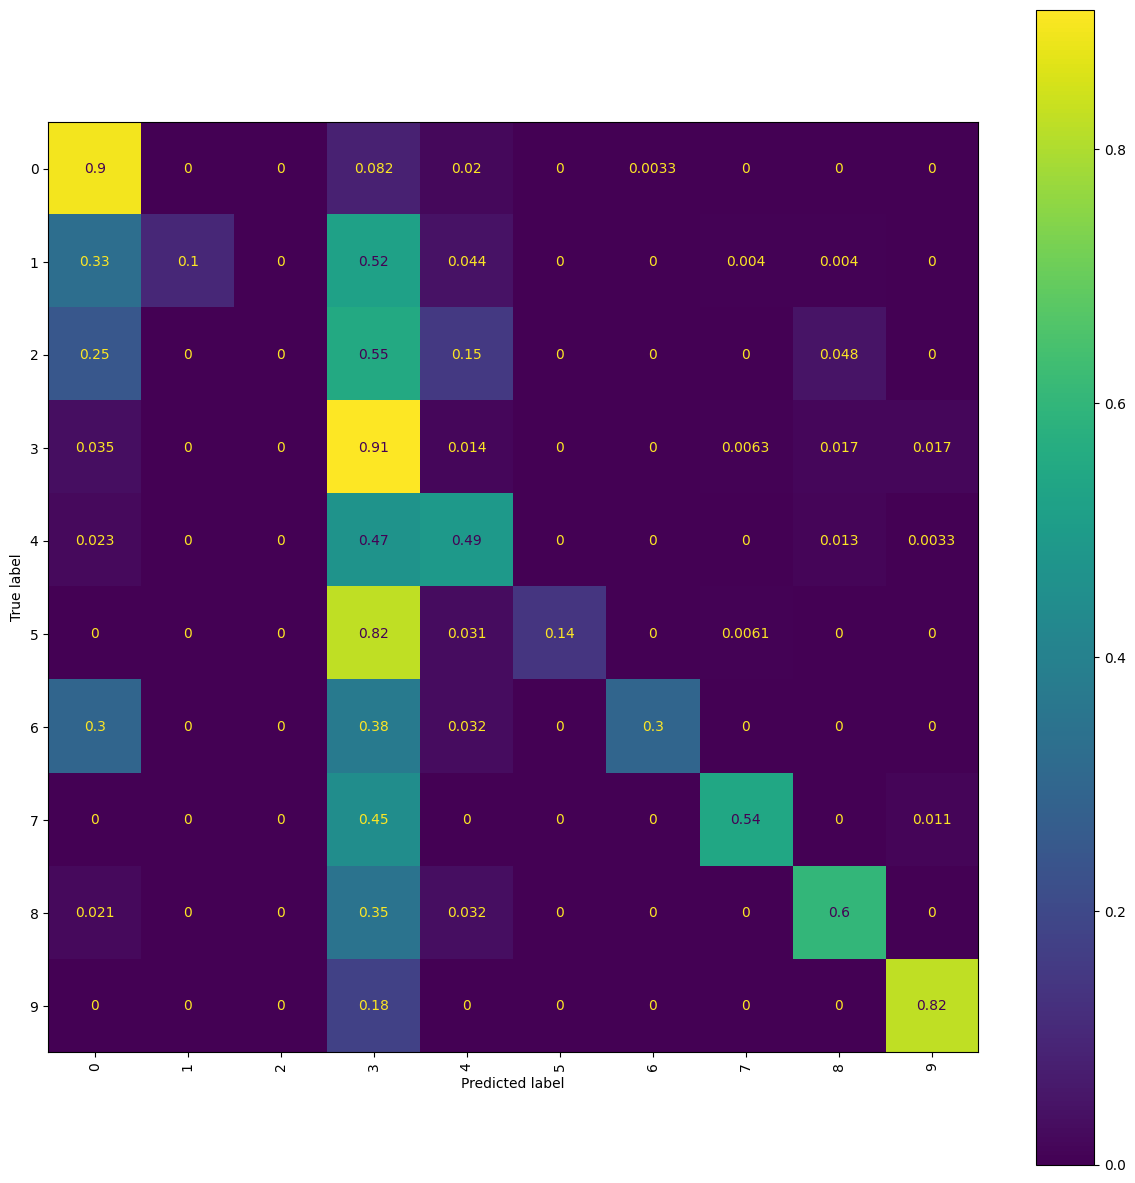

In [33]:
fig, ax = plt.subplots(figsize=(15, 15))
disp = ConfusionMatrixDisplay.from_estimator(nb_classifier, val_feature_vects, val_labels, normalize='true', xticks_rotation='vertical', ax=ax)

In [34]:
print(metrics.classification_report(val_labels, val_preds))

              precision    recall  f1-score   support

           0       0.58      0.90      0.70       305
           1       1.00      0.10      0.18       250
           2       0.00      0.00      0.00       105
           3       0.41      0.91      0.56       630
           4       0.70      0.49      0.58       301
           5       1.00      0.14      0.25       163
           6       0.98      0.30      0.46       189
           7       0.96      0.54      0.69       275
           8       0.89      0.60      0.72       281
           9       0.95      0.82      0.88       322

    accuracy                           0.60      2821
   macro avg       0.75      0.48      0.50      2821
weighted avg       0.73      0.60      0.56      2821



c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(r

Let's assume for now that we can't get or generate more data.

Next, we can try tuning a hyperparameter on the classifier. For Naive Bayes, we'll adjust the the *alpha* smoothing factor we discussed in the slides. But rather than trying a bunch ourselves, we can use a combination of **Grid Search** and **Cross Validation**.
- Grid search involves having the computer try a list of hyperparameter values for us, and returning the best performing value. The list of hyperparameter values to try is supplied by us. Grid search is a basic technique and there are a number of other techniques such as **random search** and **bayesian optimization**.
- Cross validation is a way to evaluate machine learning models on limited datasets. It randomly splits the data into k-groups. One group is set aside as the holdout set while the classifier trains a model on the remaining groups. The resulting model is then used on the holdout group and the score recorded. This repeats itself until all groups have been used as a holdout set and an average score returned.

Scikit-learn has modules to handle both for us:<br>
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html<br>
https://scikit-learn.org/stable/modules/grid_search.html#grid-search<br>
https://scikit-learn.org/stable/modules/cross_validation.html<br>


In [35]:
# The alpha values to try.
params = {'alpha': [0.01, 0.1, 0.5, 1.0, 10.0,],}

# Instantiate the search with the model we want to try and fit it on the training data.
multinomial_nb_grid = model_selection.GridSearchCV(MultinomialNB(), param_grid=params, scoring='f1_macro', n_jobs=-1, cv=5, verbose=5)
multinomial_nb_grid.fit(train_feature_vects, train_labels)

c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\utils\validation.py:605: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if is_sparse(pd_dtype):
c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\utils\validation.py:614: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if is_sparse(pd_dtype) or not is_extension_array_dtype(pd_dtype):


Fitting 5 folds for each of 5 candidates, totalling 25 fits


GridSearchCV(cv=5, estimator=MultinomialNB(), n_jobs=-1,
             param_grid={'alpha': [0.01, 0.1, 0.5, 1.0, 10.0]},
             scoring='f1_macro', verbose=5)

The resulting **GridSearchCV** object has a number of attributes you can explore:<br>
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
<br><br>
We're interested in the best performing parameter value(s).

In [36]:
print('Best parameter value(s): {}'.format(multinomial_nb_grid.best_params_))

Best parameter value(s): {'alpha': 0.01}


You can directly access the best estimator found by the search. Let's try using it on the validation set.

In [37]:
best_nb_classifier = multinomial_nb_grid.best_estimator_
val_preds = best_nb_classifier.predict(val_feature_vects)
print('Validation F1 score with fewer features: {}'.format(metrics.f1_score(val_labels, val_preds, average='macro')))

Validation F1 score with fewer features: 0.7162148612004942


So we got another decent jump after using the the optimal *alpha* value. Let's look at the confusion matrix (using the best estimator so far) and classification report again.


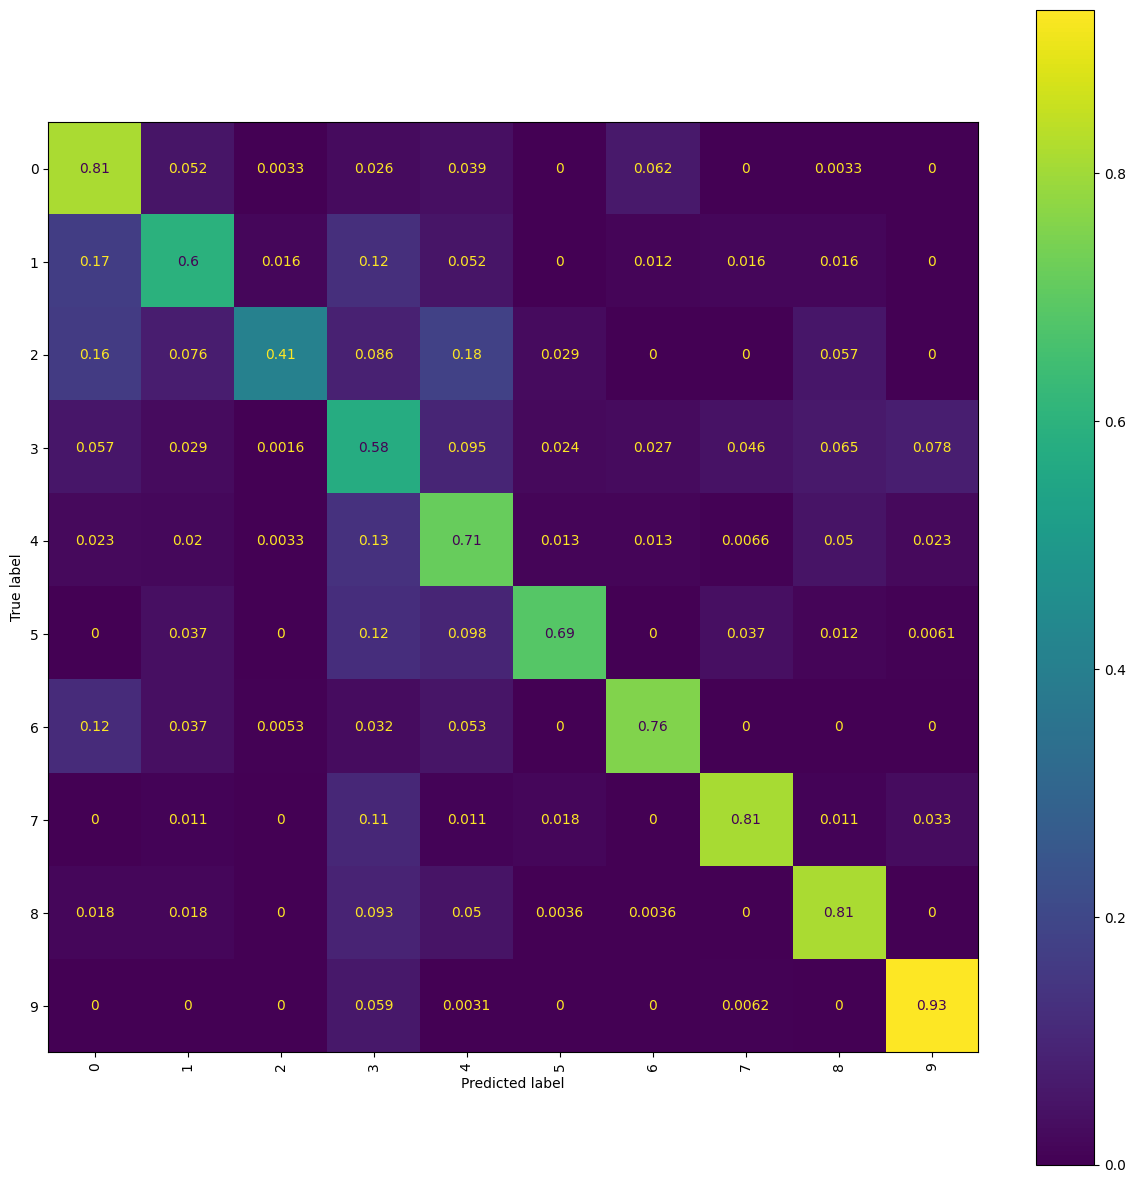

In [38]:
fig, ax = plt.subplots(figsize=(15, 15))
disp = ConfusionMatrixDisplay.from_estimator(best_nb_classifier, val_feature_vects, val_labels, normalize='true', xticks_rotation='vertical', ax=ax)

In [39]:
print(metrics.classification_report(val_labels, val_preds))

              precision    recall  f1-score   support

           0       0.66      0.81      0.73       305
           1       0.68      0.60      0.64       250
           2       0.84      0.41      0.55       105
           3       0.66      0.58      0.62       630
           4       0.59      0.71      0.65       301
           5       0.80      0.69      0.74       163
           6       0.76      0.76      0.76       189
           7       0.84      0.81      0.82       275
           8       0.76      0.81      0.79       281
           9       0.82      0.93      0.87       322

    accuracy                           0.72      2821
   macro avg       0.74      0.71      0.72      2821
weighted avg       0.72      0.72      0.71      2821



Given the small data size and the soft borders around various topics, what we have now is probably good enough. A few further ideas to explore:
1. Augment the training data with posts from similar subreddits.
2. Incorporate n-grams.
3. Remove the *misc* categories if your goal allows it.
4. Merge a few categories with large overlap together if your goal allows it.
5. Use the **CountVectorizer** instead of the **TfidfVectorizer**.
6. Play around with adding more stop words after seeing which ones are the most prevalent.
7. Play with the min_df, max_df, and max_features in the **TFidfVectorizer**.
8. Use a dimensionality reduction technique like Singular Value Decomposition (SVD) or dense word vectors which we'll cover in Part II.
9. Try other models: logistic regression, support vector machines, random forests, SGD classifier.

My guess is that, aside from merging categories, it'll be hard to do much better than what we have given the nature of the data.

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
<br>
https://scikit-learn.org/stable/modules/svm.html#svm-classification
<br>
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
<br>
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html



For idea **(6)**, we can use the function below to view the most commonly occurring words in each category.

In [40]:
def show_top_words(classifier, vectorizer, categories, top_n):
  feature_names = np.asarray(vectorizer.get_feature_names_out())
  for i, category in enumerate(categories):
    prob_sorted = classifier.feature_log_prob_[i, :].argsort()[::-1]
    print("%s: %s" % (category, " ".join(feature_names[prob_sorted[:top_n]])))

In [41]:
show_top_words(best_nb_classifier, vectorizer, np.sort(training_corpus['labels'].unique()), 10)

0: psc layer efficiency interface pce solar cell device defect transport
1: film thin solar cell device efficiency pbi2 high defect stability
2: 2d perovskite quasi-2d 3d 2d/3d dimensional film phase spacer n
3: high + energy phase x base temperature layer property result
4: device material halide perovskite high base photodetector light optoelectronic application
5: band gap property optical electronic ev perovskite compound material thermoelectric
6: cell solar layer efficiency tandem device absorber psc pce transport
7: ceramic temperature phase dielectric x sample = magnetic + transition
8: cspbbr3 emission + quantum nc light emit qds nm nanocrystal
9: oxygen catalyst oxide activity reaction cathode catalytic co2 delta co


As a sanity check, we can use scikit-learns **DummyClassifier** which can make predictions using strategies such as "just guess the most frequently occurring class" or "make random guesses".<br>
https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

In [42]:
# Train a dummy classifier which just guesses the most frequent class.
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(train_feature_vects, train_labels)
dummy_clf.score(val_feature_vects, val_labels)

0.22332506203473945

In [43]:
# Train a dummy classifier which just guesses a class randomly.
dummy_clf = DummyClassifier(strategy="uniform")
dummy_clf.fit(train_feature_vects, train_labels)
dummy_clf.score(val_feature_vects, val_labels)

0.09429280397022333

We can see the dummy classifier is much worse.

# Creating the final Naive Bayes classifier.

Let's train the classifier we'll use on the test set. We'll use the entire original training set (including validation data) and the ideal *alpha* param.
<br>
We'll also use scikit-learn's **Pipeline** to specify a series of transformation and training steps so we can vectorize and fit a model with one call. Creating a few of these pipelines can help speed up your development and stay organized:<br>
https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html


In [44]:
text_classifier = Pipeline([
  ('vectorizer', TfidfVectorizer(tokenizer=spacy_tokenizer)),
  ('classifier', MultinomialNB(alpha=0.01))
])

In [45]:
%%time
text_classifier.fit(train_data, train_labels)

c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\sklearn\feature_extraction\text.py:528: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


CPU times: total: 59.1 s
Wall time: 2min 17s


Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(tokenizer=<function spacy_tokenizer at 0x0000016213A42DE0>)),
                ('classifier', MultinomialNB(alpha=0.01))])

In [46]:
filtered_test_corpus = val_data

We can now pass the raw test data directly to the classifier.

In [47]:
%%time
test_preds = text_classifier.predict(filtered_test_corpus)

CPU times: total: 14.6 s
Wall time: 34.7 s


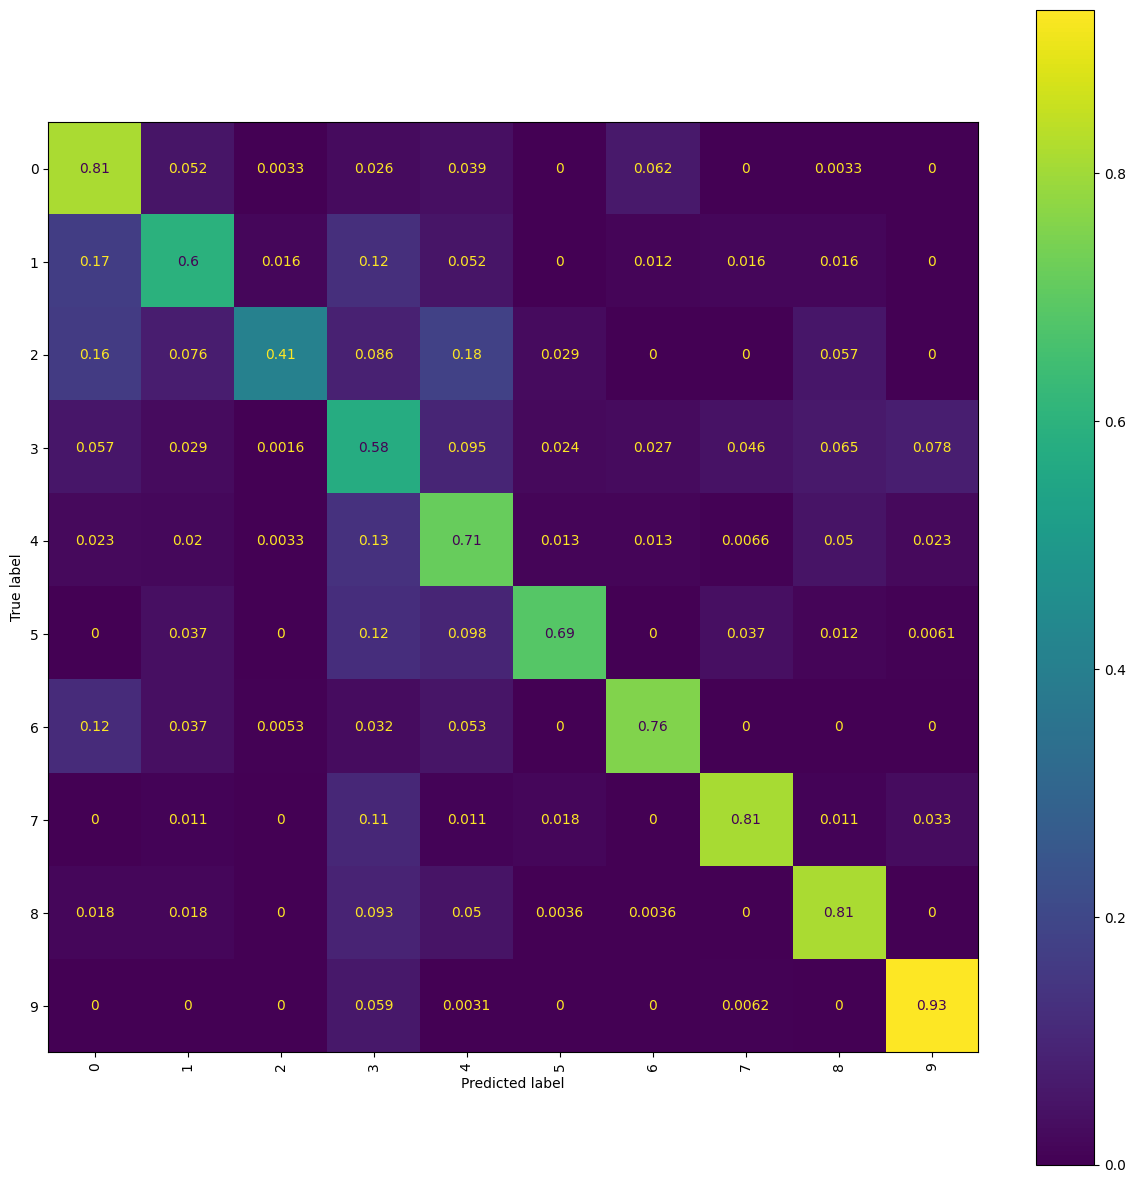

CPU times: total: 125 ms
Wall time: 611 ms


In [48]:
%%time
fig, ax = plt.subplots(figsize=(15, 15))
ConfusionMatrixDisplay.from_predictions(val_labels, test_preds, normalize='true', xticks_rotation='vertical', ax=ax)
plt.show()

We can see now that our model is working very well!
<br><br>

In [49]:
print(metrics.classification_report(val_labels, test_preds))

              precision    recall  f1-score   support

           0       0.66      0.81      0.73       305
           1       0.68      0.60      0.64       250
           2       0.84      0.41      0.55       105
           3       0.66      0.58      0.62       630
           4       0.59      0.71      0.65       301
           5       0.80      0.69      0.74       163
           6       0.76      0.76      0.76       189
           7       0.84      0.81      0.82       275
           8       0.76      0.81      0.79       281
           9       0.82      0.93      0.87       322

    accuracy                           0.72      2821
   macro avg       0.74      0.71      0.72      2821
weighted avg       0.72      0.72      0.71      2821



We can now leverage our pipeline to classify new documents on the fly now.
<br><br>
The function below takes a classifier, a document to classify, and an optional set of labels. It returns a tuple of the most probable class and its probability. With this information, you can choose a probability threshold over which to accept a classification. If it falls below the threshold, perhaps you can classify it in some default bucket or pass it to a human, or to another classifier downstream. You could also require a minimum string length for classification along with other conditions.
<br><br>


In [50]:
def classify_text(clf, doc, labels=None):
  probas = clf.predict_proba([doc]).flatten()
  max_proba_idx = np.argmax(probas)

  if labels:
    most_proba_class = labels[max_proba_idx]
  else:
    most_proba_class = max_proba_idx

  return (most_proba_class, probas[max_proba_idx])

The strings below were taken at random from subreddits that have corresponding topics (e.g. r/space, r/cars, etc).

In [57]:
labels = sorted(training_corpus['labels'].unique())
#labels = sorted(filtered_test_corpus['labels'].unique())

In [58]:
import os

dfs_2024 = []

for arquivo in os.listdir('../Data/2024/'):
    if arquivo.endswith('.xls'):
        caminho_arquivo = os.path.join('../Data/2024/', arquivo)
        
        df_temporario = pd.read_excel(caminho_arquivo)
        
        dfs_2024.append(df_temporario)

dados_total_2024 = pd.concat(dfs_2024, ignore_index=True)

In [66]:
list_topics_2024 = []

for title in dados_total_2024['Article Title']:
    classified_title = classify_text(text_classifier, title, labels)
    print(classified_title)
    list_topics_2024.append(classified_title[0])

(3, 0.49951107751316404)
(0, 0.7691661785552613)
(0, 0.8593160325247883)
(6, 0.9396860539638726)
(9, 0.9308278758302236)
(9, 0.9885492906063896)
(0, 0.41916665864723485)
(4, 0.5483856791265035)
(0, 0.834140534570642)
(1, 0.6537626239597407)
(0, 0.8949251847611276)
(0, 0.7098555252066442)
(1, 0.45165533312373357)
(3, 0.49135816468264565)
(2, 0.9514797262487033)
(4, 0.24895091055336488)
(0, 0.41498906846449074)
(5, 0.7183598759565033)
(4, 0.7371458966555376)
(8, 0.44119320440508425)
(4, 0.499974079546193)
(2, 0.8190090414905423)
(9, 0.9454605609166099)
(0, 0.5520715269523652)
(0, 0.7290689701232588)
(8, 0.6718091965652786)
(6, 0.6389193643173061)
(0, 0.7154951652198487)
(8, 0.33881828251305424)
(9, 0.6070721354896006)
(4, 0.6770435910151865)
(3, 0.556507840744607)
(5, 0.9853149495980823)
(0, 0.5272212438469489)
(6, 0.30545010686189833)
(1, 0.7733105528570339)
(1, 0.7705714262312546)
(4, 0.427649754332534)
(1, 0.43006533122664004)
(0, 0.7565705205819496)
(4, 0.6862063342029878)
(3, 0.7747

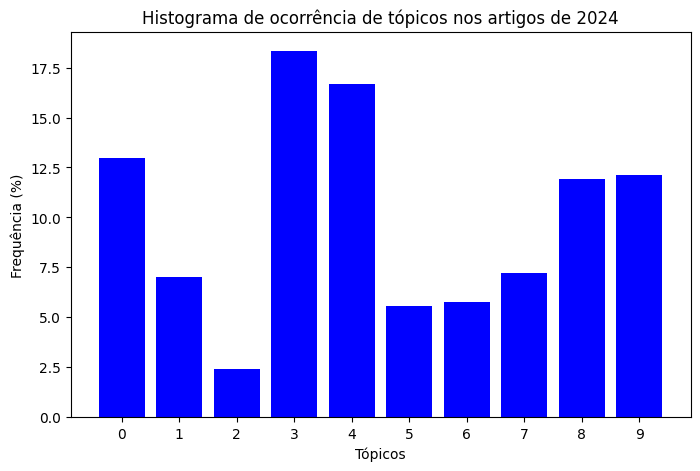

In [108]:
from collections import Counter

contagem_elementos = Counter(list_topics_2024)

total_2024 = sum(contagem_elementos.values())
freq_percentual_2024 = {k: v / total_2024 * 100 for k, v in contagem_elementos.items()}

elementos, contagens = zip(*freq_percentual_2024.items())

#elementos, contagens = zip(*contagem_elementos.items())

plt.figure(figsize=(8,5))
plt.bar(elementos, contagens, color='blue')
plt.xlabel('Tópicos')
plt.ylabel('Frequência (%)')
plt.title('Histograma de ocorrência de tópicos nos artigos de 2024')
plt.xticks([0,1,2,3,4,5,6,7,8,9])
plt.show()

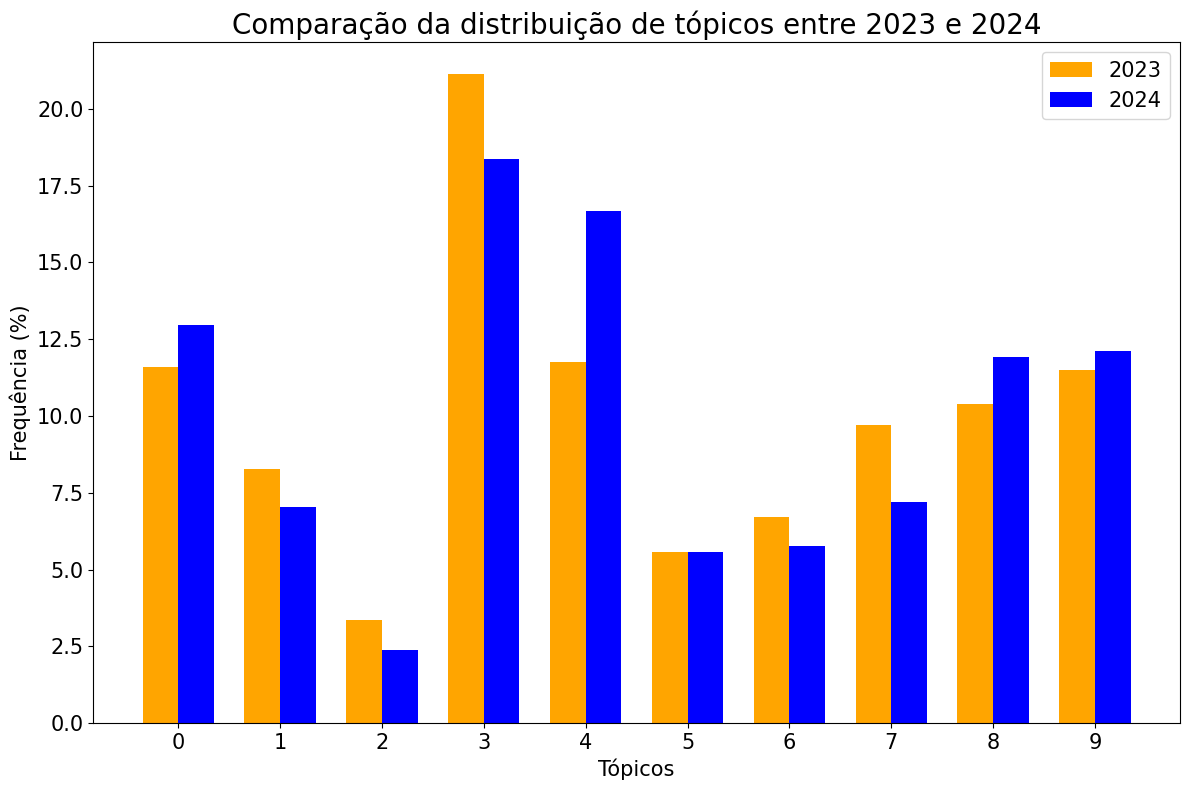

In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Dados de 2023
bins_2023, counts_2023 = np.unique(training_corpus['labels'], return_counts=True)
freq_series_2023 = pd.Series(counts_2023 / len(training_corpus['abstract']))

# Dados de 2024

contagem_elementos_2024 = Counter(list_topics_2024)

total_2024 = sum(contagem_elementos_2024.values())
freq_percentual_2024 = {k: v / total_2024 * 100 for k, v in contagem_elementos_2024.items()}

elementos_2024, contagens_2024 = zip(*freq_percentual_2024.items())

# Plotando os histogramas lado a lado
plt.figure(figsize=(12, 8))

# Barras para 2023
bar_width = 0.35
index_2023 = np.arange(len(bins_2023))
bar1 = plt.bar(index_2023, freq_series_2023*100, bar_width, label='2023', color='orange')

# Barras para 2024
index_2024 = index_2023 + bar_width
elementos_2024 = [el + bar_width for el in elementos_2024]
bar2 = plt.bar(elementos_2024, contagens_2024, bar_width, label='2024', color='blue')

plt.xlabel('Tópicos', fontsize=15)
plt.ylabel('Frequência (%)', fontsize=15)
plt.title('Comparação da distribuição de tópicos entre 2023 e 2024', fontsize=20)
plt.xticks(index_2023 + bar_width / 2, bins_2023, fontsize=15)
plt.yticks(fontsize=15)
plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

This is correct again!<br>
The titles were never feed to the model, so we seem to have a good classifier.

**Note:**<br>
Keep in mind that Naive Bayes is good at returning the most probable class but is regarded as a poor estimator because of its naive assumption of independence (i.e. the actual probability values aren't very reliable).